# Can we trust it? Uncertainty, calibration and errors of three sentence classifiers

**Module 04.2 · my implementation**, Seid Adem

> **Why this matters, in plain language.** A single score ("macro-F1 0.797") hides three questions anyone deploying a
> model must answer:
> 1. **How sure are we of that number?** On a different sample of abstracts it would come out a little different.
>    Is model A *really* better than model B, or just luckier on this test set?
> 2. **When the model says it is 99 % sure, is it right 99 % of the time?** If yes, its confidence can be used to
>    decide which predictions a human should check. If not, the confidence is decoration.
> 3. **What kind of mistakes does it make,** and do different models make different ones?
>
> ([Metrics, confusion matrices and calibration explained in the Lessons](../LESSONS.md))

The models are the three strongest from [04.1](../../01_dnn_and_transformers/implementation/), all scored on the
same official test set (29,578 sentences from 2,500 abstracts):

| Model | What it is |
|---|---|
| **LR** | TF-IDF word features + logistic regression, 400 training abstracts |
| **MLP + position** | my PyTorch network on TF-IDF + sentence position, same 400 abstracts (04.1 recipe) |
| **PubMedBERT** | the course's own fine-tuned transformer (session 1B), loaded from its saved checkpoint |

The reusable functions are in [`src/dsls/evaluation.py`](../../../src/dsls/evaluation.py) (unit-tested against
scikit-learn).

In [1]:
import warnings
from pathlib import Path

import datasets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import transformers
from datasets import load_dataset
from scipy.special import log_softmax
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, f1_score
from transformers import AutoModelForSequenceClassification, AutoTokenizer

from dsls.evaluation import (
    apply_temperature,
    bootstrap_ci,
    coverage_curve,
    expected_calibration_error,
    fit_temperature,
    paired_bootstrap,
    per_class_report,
    reliability_table,
)
from dsls.textclf import (
    MLPClassifier,
    make_loader,
    pick_device,
    position_features,
    predict_proba,
    train_with_early_stopping,
)

warnings.filterwarnings("ignore", category=FutureWarning)
datasets.utils.logging.set_verbosity_error()
transformers.logging.set_verbosity_error()
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
SEED = 0
LABELS = ["background", "objective", "methods", "results", "conclusions"]
DEVICE = pick_device()

ds = load_dataset("armanc/pubmed-rct20k")
train, val, test = (ds[s].to_pandas() for s in ("train", "validation", "test"))
for df in (train, val, test):
    df["n_sentences"] = df.groupby("abstract_id")["sentence_id"].transform("max") + 1
    df["y"] = df["label"].map(LABELS.index)
abstracts = train["abstract_id"].unique()
small = train[train["abstract_id"].isin(abstracts[:400])]  # training set, as in 04.1
calib = train[
    train["abstract_id"].isin(abstracts[-300:])
]  # never seen by any of the three models (see below)
y, groups = test["y"].to_numpy(), test["abstract_id"].to_numpy()
print(f"train {len(small):,} | calibration {len(calib):,} | test {len(test):,} sentences | device {DEVICE}")

train 4,732 | calibration 3,605 | test 29,578 sentences | device mps


> **Why a separate calibration set?** Section 4 adjusts each model's confidence using held-out data. That data must
> be unseen by the model *and* separate from the test set, or the test score is no longer an honest estimate. The
> MLP already uses the official validation set for early stopping, and the course's PubMedBERT trained on the first
> 8,000 training sentences. So I use the **last 300 training abstracts**, which no model has seen.

## 1 · Three models, one table of predictions

Every model produces, for every sentence, a **log-probability per class**. The prediction is the most probable
class; the **confidence** is that class's probability.

In [2]:
log_proba = {}  # model name → (calibration set, test set) log-probabilities

vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=50_000)
X_small = vec.fit_transform(small["text"])
logreg = LogisticRegression(max_iter=3000, C=5).fit(X_small, small["y"])
log_proba["LR"] = tuple(logreg.predict_log_proba(vec.transform(df["text"])) for df in (calib, test))


def position(df):
    return position_features(df["sentence_id"], df["n_sentences"])


mlp = MLPClassifier(X_small.shape[1] + 12, len(LABELS), seed=SEED)
train_with_early_stopping(  # identical recipe to 04.1 notebook 01
    mlp,
    make_loader(X_small, small["y"], position(small), batch_size=256, shuffle=True, seed=SEED),
    make_loader(vec.transform(val["text"]), val["y"], position(val), batch_size=1024),
    score_fn=lambda t, p: f1_score(t, p, average="macro"),
    max_epochs=30, patience=3, device=DEVICE, seed=SEED,
)  # fmt: skip
log_proba["MLP + position"] = tuple(
    np.log(
        predict_proba(mlp, make_loader(vec.transform(df["text"]), None, position(df), batch_size=1024)).clip(
            1e-12
        )
    )
    for df in (calib, test)
)

COURSE_MODEL = Path(
    "../../01_dnn_and_transformers/course_materials/local/runnable/artifacts/session1B_transformer/best_model"
)
if COURSE_MODEL.exists():
    tok = AutoTokenizer.from_pretrained(COURSE_MODEL)
    bert = AutoModelForSequenceClassification.from_pretrained(COURSE_MODEL).to(DEVICE).eval()
    to_ours = [
        [bert.config.id2label[i] for i in range(len(LABELS))].index(lab) for lab in LABELS
    ]  # reorder columns

    @torch.no_grad()
    def bert_log_proba(texts, batch_size=128):
        order, out = (
            np.argsort([len(t) for t in texts]),
            np.empty((len(texts), len(LABELS)), dtype=np.float32),
        )
        for i in range(0, len(texts), batch_size):
            idx = order[i : i + batch_size]
            enc = tok(
                [texts[j] for j in idx], truncation=True, max_length=128, padding=True, return_tensors="pt"
            )
            out[idx] = bert(**enc.to(DEVICE)).logits.float().cpu().numpy()
        return log_softmax(out[:, to_ours], axis=1)

    log_proba["PubMedBERT"] = tuple(bert_log_proba(df["text"].tolist()) for df in (calib, test))
else:
    print("course checkpoint not found: run `make runnable` and session 1B to include PubMedBERT")

MODELS = list(log_proba)
pred = {m: log_proba[m][1].argmax(1) for m in MODELS}
conf = {m: np.exp(log_proba[m][1]).max(1) for m in MODELS}
pd.DataFrame({m: {"accuracy": (pred[m] == y).mean(), "macro-F1": f1_score(y, pred[m], average="macro"),
                  "weighted-F1": f1_score(y, pred[m], average="weighted")} for m in MODELS}).T.round(3)  # fmt: skip

,accuracy,macro-F1,weighted-F1
LR,0.758,0.676,0.751
MLP + position,0.853,0.797,0.851
PubMedBERT,0.850,0.782,0.850


**Accuracy says the MLP and PubMedBERT are equal (0.853 vs 0.850); macro-F1 says the MLP is ahead (0.797 vs 0.782).**
Accuracy and weighted-F1 are dominated by the two big classes (*methods* and *results*, two-thirds of all sentences).
Macro-F1 gives the small classes equal say, and that is where the models differ. Section 3 checks whether a gap of
0.015 is real or luck.

## 2 · Beyond one number: per-class scores

> **In plain language.** For one class, say *objective*:
> * **precision** = of the sentences the model *called* objective, the share that really are ("when it says
>   objective, can I believe it?");
> * **recall** = of the sentences that really *are* objective, the share it found ("does it miss many?");
> * **F1** = a single number balancing the two (their harmonic mean, which is low if either is low).
>
> **Macro-F1** averages F1 over the five classes equally; **weighted-F1** weights each class by its size, so it is
> dominated by the big *methods* and *results* classes. Accuracy behaves like weighted-F1. ([Lessons](../LESSONS.md))

                    LR               MLP + position               PubMedBERT              
             precision recall     f1      precision recall     f1  precision recall     f1
background       0.581  0.445  0.504          0.694  0.729  0.711      0.614  0.715  0.661
objective        0.644  0.480  0.550          0.692  0.511  0.588      0.666  0.538  0.595
methods          0.798  0.899  0.845          0.870  0.924  0.896      0.920  0.935  0.928
results          0.821  0.835  0.828          0.891  0.885  0.888      0.921  0.891  0.906
conclusions      0.660  0.644  0.652          0.912  0.891  0.901      0.811  0.828  0.819
macro avg        0.701  0.661  0.676          0.812  0.788  0.797      0.786  0.782  0.782
weighted avg     0.749  0.758  0.751          0.851  0.853  0.851      0.852  0.850  0.850


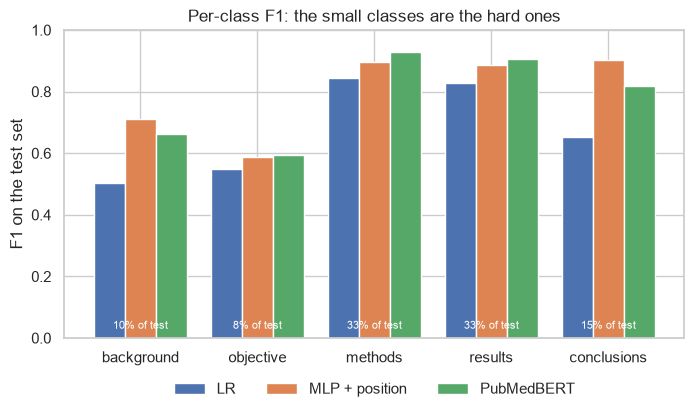

In [3]:
reports = {m: per_class_report(y, pred[m], LABELS) for m in MODELS}
f1_table = pd.DataFrame({m: r["f1"] for m, r in reports.items()})
print(
    pd.concat({m: r[["precision", "recall", "f1"]] for m, r in reports.items()}, axis=1).round(3).to_string()
)

ax = f1_table.loc[LABELS].plot.bar(figsize=(8, 4), rot=0, width=0.8)
ax.set(ylabel="F1 on the test set", ylim=(0, 1), title="Per-class F1: the small classes are the hard ones")
for lab, share in zip(LABELS, test["label"].value_counts(normalize=True)[LABELS], strict=True):
    ax.annotate(f"{share:.0%} of test", (LABELS.index(lab), 0.03), ha="center", fontsize=8, color="white")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
plt.savefig(FIGURES / "01_per_class_f1.png", dpi=150, bbox_inches="tight")
plt.show()

**The models are good at different things.**

* **PubMedBERT wins on *methods* and *results*** (F1 0.93 and 0.91 vs the MLP's 0.90 and 0.89): the big classes,
  where the wording alone gives the answer ("Patients were randomized…", "…was significantly lower").
* **The MLP wins on *conclusions* (0.90 vs 0.82) and *background* (0.71 vs 0.66)**, the classes that sit at the end
  and the start of an abstract. It knows the sentence's position; PubMedBERT doesn't.
* **Everyone struggles with *objective*** (F1 0.55–0.60), the smallest class (8 % of sentences). Recall is only about
  0.5: half of the objective sentences are missed.

This is why a per-class view matters: one average would hide that the "best" model depends on which class you care
about. In a literature-mining tool that extracts study *objectives*, all three models would disappoint.

## 3 · How sure are we of the score? Bootstrap intervals

> **In plain language.** The test set is one sample of abstracts. To see how much the score would wobble on another
> sample, the **bootstrap** re-draws the test set many times *with replacement* (some abstracts twice, some not at
> all), recomputes the score each time, and reports the range covering the middle 95 % of results.
>
> Two details matter:
> * **Resample abstracts, not sentences.** Sentences from one abstract share a topic and writing style, so they tend
>   to be right or wrong together. Treating them as independent would make the range too narrow.
> * **To compare two models, use the *same* resamples for both** (a *paired* bootstrap). Both models face the same
>   easy and hard abstracts each time, so luck cancels out and the comparison is much sharper.

In [4]:
rows = []
for m in MODELS:
    by_abstract = bootstrap_ci(y, pred[m], "macro_f1", groups=groups, n_classes=len(LABELS))
    by_sentence = bootstrap_ci(y, pred[m], "macro_f1", n_classes=len(LABELS))
    rows.append({"model": m, "macro-F1": by_abstract["estimate"],
                 "95% interval (resampling abstracts)": f"{by_abstract['low']:.3f} – {by_abstract['high']:.3f}",
                 "95% interval (resampling sentences)": f"{by_sentence['low']:.3f} – {by_sentence['high']:.3f}"})  # fmt: skip
pd.DataFrame(rows).round(3)

,model,macro-F1,95% interval (resampling abstracts),95% interval (resampling sentences)
0,LR,0.676,0.668 – 0.683,0.669 – 0.683
1,MLP + position,0.797,0.790 – 0.804,0.791 – 0.802
2,PubMedBERT,0.782,0.775 – 0.788,0.776 – 0.788


In [5]:
pairs = [("MLP + position", "LR"), ("MLP + position", "PubMedBERT"), ("PubMedBERT", "LR")]
rows = []
for a, b in pairs:
    if a in pred and b in pred:
        r = paired_bootstrap(y, pred[a], pred[b], "macro_f1", groups=groups, n_classes=len(LABELS))
        rows.append({"comparison": f"{a} − {b}", "difference": r["difference"],
                     "95% interval": f"{r['low']:+.3f} to {r['high']:+.3f}", "A better in": f"{r['share_a_better']:.0%}"})  # fmt: skip
pd.DataFrame(rows).round(3)

,comparison,difference,95% interval,A better in
0,MLP + position − LR,0.121,+0.115 to +0.127,100%
1,MLP + position − PubMedBERT,0.015,+0.009 to +0.022,100%
2,PubMedBERT − LR,0.106,+0.099 to +0.113,100%


**Each score is pinned down to about ±0.007, and the MLP's lead over PubMedBERT is real.**

* The individual 95 % intervals of the MLP (0.790–0.804) and PubMedBERT (0.775–0.788) almost touch, which might
  suggest "too close to call". The **paired** bootstrap, which puts both models on the same resampled abstracts,
  gives a much sharper answer: the MLP is ahead by **+0.015 (95 % interval +0.009 to +0.022)** and ahead in virtually
  all of the 1,000 resamples (the table rounds to 100 %).
* **Resampling abstracts vs sentences** gives nearly the same intervals here. Sentences within one abstract are only
  weakly linked in how hard they are. It's still the safer default: with patients, hospitals or families, the
  difference is often large.

> **In plain language.** Always report a range, not just a score. And to decide which of two models is better, compare
> them on the *same* resampled data: comparing two separate ranges is much less sensitive.

*Caveat:* the bootstrap measures uncertainty from **which test abstracts** were drawn. It doesn't cover other sources
of variation, such as a different random seed or a different set of 400 training abstracts.

## 4 · Do different models make different mistakes?

> **In plain language.** A **confusion matrix** counts, for each true class (rows), what the model predicted
> (columns). Normalised so each row sums to 1, the diagonal is each class's recall and everything off the diagonal is
> a specific kind of mistake.

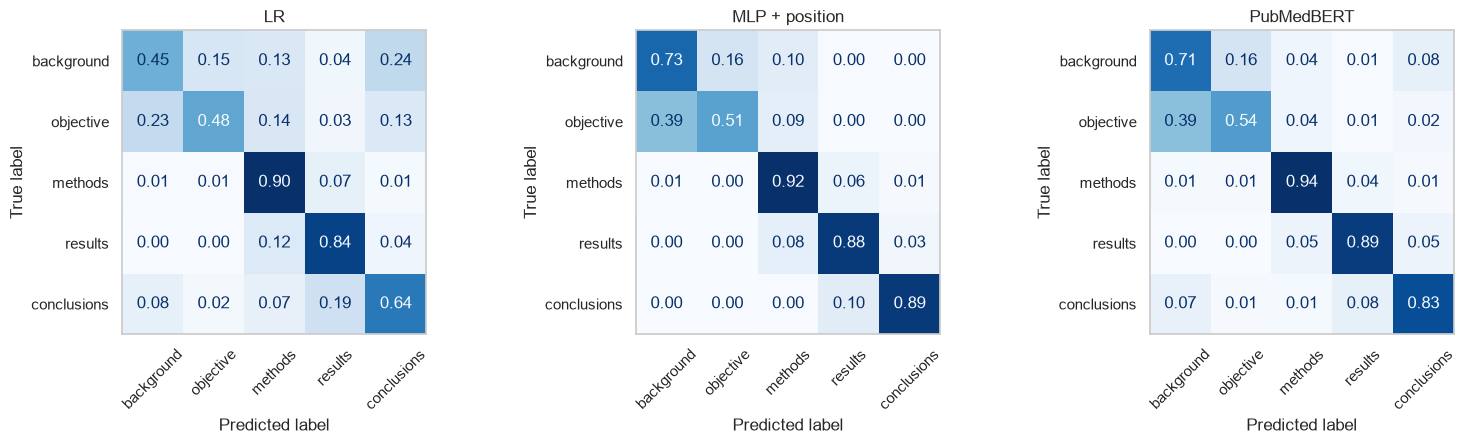

both right                   0.779
only MLP + position right    0.075
only PubMedBERT right        0.071
both wrong                   0.075


In [6]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(5.2 * len(MODELS), 4.6))
for ax, m in zip(np.atleast_1d(axes), MODELS, strict=True):
    ConfusionMatrixDisplay.from_predictions(y, pred[m], display_labels=LABELS, normalize="true", values_format=".2f",
                                            cmap="Blues", colorbar=False, ax=ax, xticks_rotation=45)  # fmt: skip
    ax.set_title(m)
    ax.grid(False)
fig.tight_layout()
fig.savefig(FIGURES / "02_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

if "PubMedBERT" in pred:
    a, b = pred["MLP + position"] == y, pred["PubMedBERT"] == y
    print(pd.Series({"both right": (a & b).mean(), "only MLP + position right": (a & ~b).mean(),
                     "only PubMedBERT right": (~a & b).mean(), "both wrong": (~a & ~b).mean()}).round(3).to_string())  # fmt: skip

**The hardest confusion is the same for every model: 39 % of *objective* sentences are called *background*** by both
the MLP and PubMedBERT (and 16 % of background sentences go the other way). Both sit at the start of the abstract and
use similar language ("…remains unclear. We therefore assessed…").

**Position explains the other big difference.** Without it, LR calls 24 % of *background* sentences *conclusions*:
both are general statements about the field ("X is a major cause of…" vs "X is an effective treatment for…"). The MLP,
which knows the sentence's position, almost never makes that mistake (0.00); PubMedBERT reads the wording better than
LR but can't see the position (0.08).

**The two strong models fail on different sentences:** each is right on about 7–8 % of sentences that the other gets
wrong, and only 7.5 % defeat both. Models that err differently are worth combining (section 7).

## 5 · Calibration: does "90 % sure" mean right 90 % of the time?

> **In plain language.** A weather forecaster is **well calibrated** if, on all the days they said "70 % chance of
> rain", it rained on about 70 % of them. For a classifier: group predictions by confidence and compare each group's
> average confidence with its actual accuracy. Plotted, that is a **reliability diagram**: a perfectly calibrated
> model sits on the diagonal; below it means **over-confident** (claims more than it delivers), above it means
> **under-confident**. The **expected calibration error (ECE)** summarises the gap in one number: the average
> distance from the diagonal, weighted by how many predictions are in each group (0 = perfect). ([Lessons](../LESSONS.md))
>
> **Temperature scaling** is the standard fix: divide the model's scores by one number *T*, chosen on the calibration
> set. *T* > 1 softens an over-confident model, *T* < 1 sharpens an under-confident one. The predicted class never
> changes, so accuracy and F1 stay exactly the same: only the confidence becomes honest.

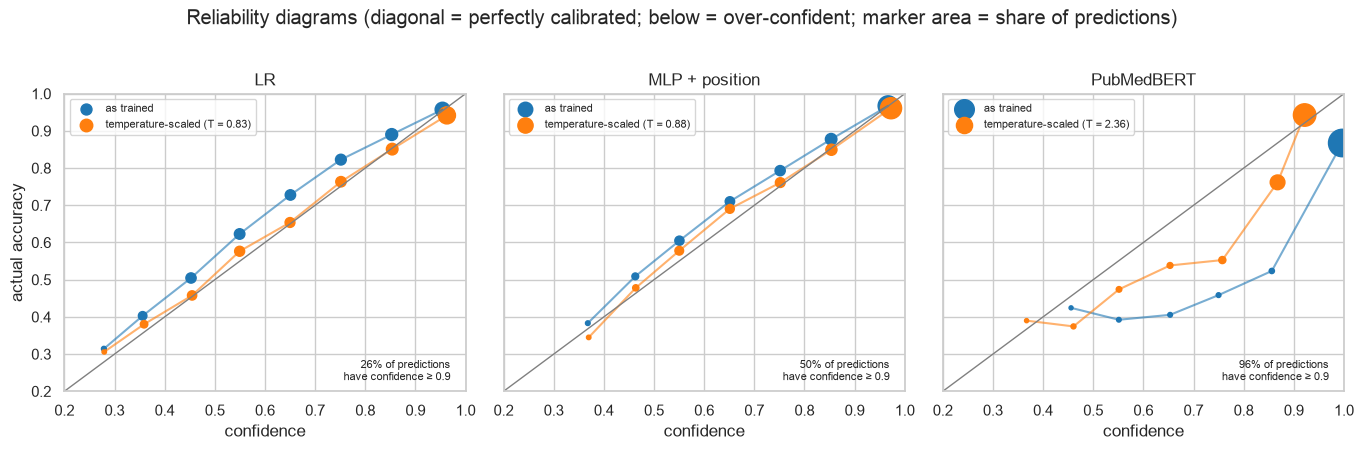

,model,accuracy,mean confidence,ECE,temperature,ECE after scaling
0,LR,0.758,0.714,0.045,0.831,0.014
1,MLP + position,0.853,0.832,0.021,0.883,0.014
2,PubMedBERT,0.850,0.985,0.135,2.356,0.056


In [7]:
temperature = {m: fit_temperature(log_proba[m][0], calib["y"]) for m in MODELS}
conf_T = {m: apply_temperature(log_proba[m][1], temperature[m]).max(1) for m in MODELS}

fig, axes = plt.subplots(1, len(MODELS), figsize=(4.6 * len(MODELS), 4.4), sharey=True)
rows = []
for ax, m in zip(np.atleast_1d(axes), MODELS, strict=True):
    for c, colour, name in (
        (conf[m], "tab:blue", "as trained"),
        (conf_T[m], "tab:orange", f"temperature-scaled (T = {temperature[m]:.2f})"),
    ):
        t = reliability_table(c, pred[m] == y, n_bins=10)
        t = t[t["count"] >= 30]  # bins with a handful of predictions are noise, not evidence
        ax.plot(t["mean_confidence"], t["accuracy"], "-", color=colour, alpha=0.6)
        ax.scatter(
            t["mean_confidence"], t["accuracy"], s=8 + 400 * t["count"] / len(y), color=colour, label=name
        )
    ax.plot([0, 1], [0, 1], color="grey", lw=1)
    ax.set(title=m, xlabel="confidence", xlim=(0.2, 1), ylim=(0.2, 1))
    ax.text(
        0.97,
        0.23,
        f"{(conf[m] >= 0.9).mean():.0%} of predictions\nhave confidence ≥ 0.9",
        ha="right",
        fontsize=8,
    )
    ax.legend(loc="upper left", fontsize=8)
    rows.append({"model": m, "accuracy": (pred[m] == y).mean(), "mean confidence": conf[m].mean(),
                 "ECE": expected_calibration_error(conf[m], pred[m] == y), "temperature": temperature[m],
                 "ECE after scaling": expected_calibration_error(conf_T[m], pred[m] == y)})  # fmt: skip
np.atleast_1d(axes)[0].set_ylabel("actual accuracy")
fig.suptitle(
    "Reliability diagrams (diagonal = perfectly calibrated; below = over-confident; marker area = share of predictions)",
    y=1.02,
)
fig.tight_layout()
fig.savefig(FIGURES / "03_reliability.png", dpi=150, bbox_inches="tight")
plt.show()
pd.DataFrame(rows).round(3)

**PubMedBERT is badly over-confident; the two simpler models are honest.**

| | LR | MLP + position | PubMedBERT |
|---|---|---|---|
| accuracy | 0.758 | 0.853 | 0.850 |
| average confidence | 0.714 | 0.832 | **0.985** |
| predictions with confidence ≥ 0.9 | 26 % | 50 % | **96 %** |
| ECE (0 = perfect) | 0.045 | 0.021 | **0.135** |
| ECE after temperature scaling | 0.014 | 0.014 | 0.056 |

* **PubMedBERT claims to be at least 90 % sure about 96 % of sentences, but it is right on 85 %.** Its largest group
  of predictions (28,311 sentences) averages 99.6 % confidence with 87 % accuracy. This is typical of large networks trained until
  the training loss is tiny: they learn to push probabilities towards 0 and 1 (Guo et al., 2017, *On calibration of
  modern neural networks*).
* **Temperature scaling (T = 2.36) cuts its error from 0.135 to 0.056,** but can't remove it. The top group lands on
  the diagonal, while the middle groups stay well below (at 75 % confidence it is right only 55 % of the time). One
  number can rescale confidences but can't fix their *shape*.
* **LR and the MLP are slightly under-confident** (T < 1, curves just above the diagonal). Regularisation (logistic
  regression's penalty, the MLP's dropout and weight decay) keeps them modest. One number fixes them almost perfectly
  (ECE 0.014).

> **Why it matters at work.** If a team routes "low-confidence" predictions to human review, an over-confident model
> sends almost nothing for review, and its errors go out unchecked. Check calibration before using a confidence score
> for any decision.

## 6 · Using confidence: let the model answer only when it is sure

> **In plain language.** In practice, a model can label the sentences it is confident about and pass the rest to a
> person. The **coverage curve** shows the trade-off: the accuracy on the most confident 90 %, 80 %, … of sentences.
> This only works if the model's confidence *ranks* its predictions well, i.e. its confident predictions really are
> its correct ones.

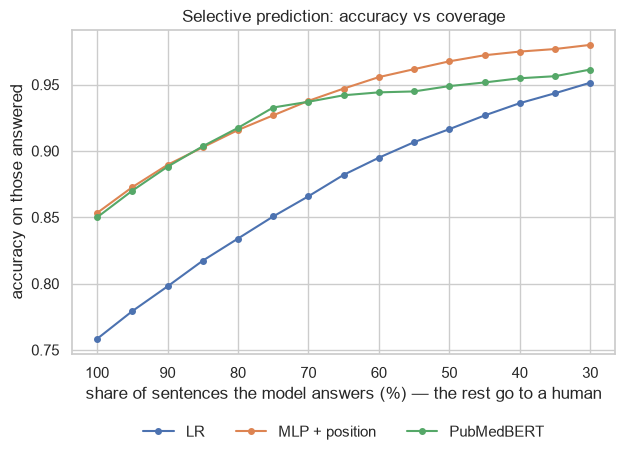

,LR,MLP + position,PubMedBERT
coverage,,,
1.00,0.758,0.853,0.850
0.90,0.798,0.890,0.888
0.80,0.834,0.916,0.917
0.65,0.882,0.947,0.942
0.30,0.951,0.980,0.961


In [8]:
curves = {m: coverage_curve(conf_T[m], pred[m] == y, coverages=np.linspace(1, 0.3, 15)) for m in MODELS}
fig, ax = plt.subplots(figsize=(7, 4.2))
for m, c in curves.items():
    ax.plot(c["coverage"] * 100, c["accuracy"], "o-", ms=4, label=m)
ax.invert_xaxis()
ax.set(xlabel="share of sentences the model answers (%) — the rest go to a human", ylabel="accuracy on those answered",
       title="Selective prediction: accuracy vs coverage")  # fmt: skip
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
fig.savefig(FIGURES / "04_coverage.png", dpi=150, bbox_inches="tight")
plt.show()
pd.DataFrame({m: c.set_index("coverage")["accuracy"] for m, c in curves.items()}).iloc[
    [0, 2, 4, 7, 14]
].round(3)

**Confidence is useful for triage, but PubMedBERT's saturated confidence ranks its answers less well.**

* All models get more accurate as they answer less: answering the most confident 80 %, the MLP and PubMedBERT both
  reach 0.92 accuracy (from 0.85).
* **Below about 70 % coverage, PubMedBERT's curve flattens.** Answering only the 30 % it is surest about, it is right
  96.1 % of the time against the MLP's **98.0 %**. Even LR, a much weaker model overall, reaches 95.1 %. When 89 % of
  its raw scores are above 0.99, the model can't tell its safest answers from merely likely ones.

*(The curves use the temperature-scaled confidences.)*

## 7 · Combining models that make different mistakes

Section 4 showed the MLP (which knows the sentence's position) and PubMedBERT (which reads the words far better)
often fail on *different* sentences. The simplest combination: average their temperature-scaled probabilities.
Calibration matters here: averaging an over-confident model with a modest one would let the loud one dominate.

In [9]:
if "PubMedBERT" in pred:
    proba_T = {
        m: apply_temperature(log_proba[m][1], temperature[m]) for m in ("MLP + position", "PubMedBERT")
    }
    pred["average of the two"] = ((proba_T["MLP + position"] + proba_T["PubMedBERT"]) / 2).argmax(1)
    for other in ("PubMedBERT", "MLP + position"):
        r = paired_bootstrap(
            y, pred["average of the two"], pred[other], "macro_f1", groups=groups, n_classes=len(LABELS)
        )
        print(
            f"average − {other:15s}: {r['difference']:+.3f} macro-F1 (95% interval {r['low']:+.3f} to {r['high']:+.3f})"
        )
    print("average: accuracy", round((pred["average of the two"] == y).mean(), 3),
          "| macro-F1", round(f1_score(y, pred["average of the two"], average="macro"), 3))  # fmt: skip

average − PubMedBERT     : +0.033 macro-F1 (95% interval +0.029 to +0.036)


average − MLP + position : +0.018 macro-F1 (95% interval +0.012 to +0.024)
average: accuracy 0.876 | macro-F1 0.814


**Averaging the two calibrated models gives macro-F1 0.814 (accuracy 0.876)**: +0.033 over PubMedBERT and +0.018
over the MLP, both clearly beyond resampling noise. The MLP contributes the position, PubMedBERT the reading.

For comparison, [04.1 notebook 02](../../01_dnn_and_transformers/implementation/02_small_biomedical_transformers.ipynb)
fed the position to PubMedBERT directly as text and reached 0.847. **Giving one model all the information beat
combining two models that each lack part of it.** Combining is the fallback when you can't retrain.

## 8 · Reading the mistakes the model was surest about

> **In plain language.** Numbers say *how often* a model fails; reading the failures says *why*. The most useful
> ones to read are the **confident mistakes**: sentences where the model was very sure and still "wrong". They are
> either real blind spots, or cases where the *label* is debatable.

In [10]:
m = "PubMedBERT" if "PubMedBERT" in pred else "MLP + position"
wrong = test.assign(predicted=[LABELS[p] for p in pred[m]], confidence=conf_T[m])[pred[m] != y]
pd.set_option("display.max_colwidth", 140)
print(f"{m}: {len(wrong):,} errors; the 10 most confident:")
wrong.nlargest(10, "confidence")[
    ["text", "label", "predicted", "confidence", "sentence_id", "n_sentences"]
].round(3)

PubMedBERT: 4,439 errors; the 10 most confident:


,text,label,predicted,confidence,sentence_id,n_sentences
20988,Ocular hypertensive subjects ( with IOP correction for CCT and corneal curvature ) as compared to ocular normotensive subjects had a sig...,conclusions,results,0.938,8,10
27278,"A positive correlation between late effectors of mTORC@ activation , a positive correlation between Akt-independent mTORC@ activation , ...",conclusions,results,0.938,11,13
26033,No serious adverse event related to SprayShield was observed .,conclusions,results,0.938,12,15
3585,There were no significant differences between study groups regarding the complications .,conclusions,results,0.938,9,11
5813,"In @ patients the PSA remained above thresholds ( median @ , range @-@ @ ng/mL ) .",methods,results,0.938,4,14
22454,"Patients who chewed gum postoperatively had less POI , passed flatus sooner , had an earlier bowel movement and a shorter length of stay...",conclusions,results,0.938,8,10
11850,Comparable numbers of patients experienced BCG therapy-related side effects in each treatment group ( p = @ ) .,conclusions,results,0.938,11,18
18852,"Of the @ dogs receiving placebo , @ ( @ % ) vomited and @ ( @ % ) developed signs of nausea ; overall , @ of @ ( @ % ) dogs in the place...",methods,results,0.937,7,11
1256,"Pain scores were similar among groups , and all @ groups had similar rescue analgesia requirements and similar times to first administra...",conclusions,results,0.937,10,12
13736,RESULST : Graybiel ' s score and grading of severity had no difference between two groups through acclimatization training ( P > @ ) .,methods,results,0.937,6,9


**The confident "mistakes" are mostly debatable labels, not model blind spots.** All ten are predicted *results*.
Reading them:

* *"No serious adverse event related to SprayShield was observed."*, *"There were no significant differences between
  study groups regarding the complications."* and *"Pain scores were similar among groups…"* are labelled
  **conclusions**, yet they report findings. The authors put them in their *Conclusions* section; the model reads
  them, reasonably, as results.
* *"Of the @ dogs receiving placebo, @ (@ %) vomited…"* is labelled **methods**: a plain result, filed under the
  wrong heading.
* One sentence labelled **methods** literally begins *"RESULST : Graybiel's score … had no difference between two
  groups"*. The heading itself, typo included, ended up inside the sentence.

The labels in PubMed RCT come from the **section headings authors chose**, not from annotators checking every
sentence, so some "errors" are label noise. That sets a ceiling on any model's score and is worth knowing before
spending weeks chasing the last percent.

*Note:* after temperature scaling, all ten show the same confidence (0.938). PubMedBERT's raw scores for these
sentences are so extreme that they all hit the same ceiling, the saturation seen in section 6.

## Conclusions

1. **Report per-class scores:** accuracy said "tie"; per-class F1 showed PubMedBERT is better on the big classes and
   the MLP on the positional ones (*background*, *conclusions*), while *objective* defeats all three.
2. **Report uncertainty, and compare models with a paired test:** each macro-F1 is known to about ±0.007. The MLP's
   0.015 lead over PubMedBERT is real (+0.009 to +0.022), which two separate intervals alone couldn't show.
3. **Check calibration before trusting a confidence score:** PubMedBERT says "≥ 90 % sure" 96 % of the time but is
   right 85 % of the time (ECE 0.135). Temperature scaling helps (0.056) but can't fully fix it; the two regularised
   models were nearly calibrated from the start.
4. **Confidence-based triage works best with an honest model:** answering its surest 30 %, the MLP is right 98.0 %
   of the time, PubMedBERT 96.1 %.
5. **Models that fail differently combine well** (+0.033), but giving one model all the information did better
   (0.847 in 04.1).
6. **Read the mistakes:** the most confident ones are mostly label noise from authors' section headings, which limits
   what any model can reach.

*Runtime: about 5 minutes on an Apple-silicon laptop (GPU via MPS); PubMedBERT inference is most of it. The
PubMedBERT section needs the course's 1B checkpoint (`make runnable`, then run 1B); without it, the notebook runs
with the other two models.*